# Heart disease replication and XAI extension

The replication follows the paper's equal training/test partition and compares its logistic-regression, SVM, and neural-network families. The implementation uses a fixed stratified split for reproducibility and fits standardisation on the training partition only; these are explicit implementation and leakage-control choices. Test metrics are reported descriptively and are not used to select the XAI model. The 10-fold L2 logistic-regression variant is pre-specified for the XAI extension.

In [1]:
# Dependencies are installed from the repository lock file, not inside the notebook.
# See requirements-xai-lock.txt and README.md.

In [2]:
# The replication uses the versioned local Cleveland file under data/heart.
# No network download is required during notebook execution.

In [3]:
# Data provenance: UCI Heart Disease (Cleveland processed file).
# Source: https://archive.ics.uci.edu/dataset/45/heart+disease
# The local input is loaded in the next cell.

In [4]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegressionCV, LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score, roc_curve, auc
from sklearn.cluster import KMeans
from sklearn.kernel_approximation import RBFSampler
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.metrics import pairwise_distances
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import SGD
import shap
import lime
import lime.lime_tabular
import matplotlib.pyplot as plt
from sklearn.metrics.pairwise import euclidean_distances

file_path = "../../data/heart/processed.cleveland.data"

# column names -> defined manually
column_names = [
    'age', 'sex', 'cp', 'trestbps', 'chol', 'fbs',
    'restecg', 'thalach', 'exang', 'oldpeak',
    'slope', 'ca', 'thal', 'target'
]

df = pd.read_csv(file_path, names=column_names)

# replace missing values '?'
df.replace('?', np.nan, inplace=True)

# conversion numeric columns
for col in df.columns:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# drop missing values
df = df.dropna()

# conversion to binary classification
df['target'] = df['target'].apply(lambda x: 1 if x > 0 else 0)

X = df.drop('target', axis=1)
y = df['target']

feature_names = X.columns.tolist()

# The source paper uses equal training and test subsets. Split before
# learning preprocessing parameters to prevent test-data leakage.
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y,
    test_size=0.50,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()
X_train = pd.DataFrame(
    scaler.fit_transform(X_train_raw),
    columns=feature_names,
    index=X_train_raw.index,
)
X_test = pd.DataFrame(
    scaler.transform(X_test_raw),
    columns=feature_names,
    index=X_test_raw.index,
)

c:\Users\catia\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [5]:
import sys
from pathlib import Path

# Notebook is in thesis/src/replication
# Framework is in thesis/src/xai_framework
FRAMEWORK_DIR = Path.cwd().parent / "xai_framework"

if str(FRAMEWORK_DIR) not in sys.path:
    sys.path.insert(0, str(FRAMEWORK_DIR))

from run_pipeline import run_pipeline

In [6]:
# LR with 5-fold and 10-fold CV
lr_5fold = LogisticRegressionCV(Cs=10, cv=5, penalty='l2', solver='liblinear', max_iter=1000, random_state=42)
lr_10fold = LogisticRegressionCV(Cs=10, cv=10, penalty='l2', solver='liblinear', max_iter=1000, random_state=42)

lr_5fold.fit(X_train, y_train)
lr_10fold.fit(X_train, y_train)

y_pred_lr_5fold = lr_5fold.predict(X_test)
y_pred_lr_10fold = lr_10fold.predict(X_test)

print("Logistic Regression (5-fold CV) Test Accuracy:", accuracy_score(y_test, y_pred_lr_5fold))
print("Logistic Regression (5-fold CV) F1 Score:", f1_score(y_test, y_pred_lr_5fold))
print("Logistic Regression (10-fold CV) Test Accuracy:", accuracy_score(y_test, y_pred_lr_10fold))
print("Logistic Regression (10-fold CV) F1 Score:", f1_score(y_test, y_pred_lr_10fold))

Logistic Regression (5-fold CV) Test Accuracy: 0.8523489932885906
Logistic Regression (5-fold CV) F1 Score: 0.8405797101449275
Logistic Regression (10-fold CV) Test Accuracy: 0.8523489932885906
Logistic Regression (10-fold CV) F1 Score: 0.8405797101449275


In [7]:
y_score_lr = lr_10fold.predict_proba(X_test)[:, 1]

fpr_lr, tpr_lr, _ = roc_curve(
    y_test,
    y_score_lr
)

auc_lr = auc(
    fpr_lr,
    tpr_lr
)

print(
    f"Logistic Regression AUC: {auc_lr:.2f}"
)

Logistic Regression AUC: 0.92


In [8]:
#test check
print("Unique values in y_train:", np.unique(y_train))
print("Unique values in y_test:", np.unique(y_test))
print("Missing values in y_train:", y_train.isnull().sum())
print("Missing values in y_test:", y_test.isnull().sum())

Unique values in y_train: [0 1]
Unique values in y_test: [0 1]
Missing values in y_train: 0
Missing values in y_test: 0


In [9]:
param_grid_linear = {
    'C': [0.1, 1, 10],
    'kernel': ['linear']
}

param_grid_rbf = {
    'C': [1, 10],
    'gamma': [0.1, 0.01],
    'kernel': ['rbf']
}

param_grid_poly = {
    'C': [1, 10],
    'gamma': ['scale'],
    'degree': [2, 3],
    'kernel': ['poly']
}

In [10]:
# ===== LINEAR SVM 5-FOLD =====
svm_linear_5 = GridSearchCV(
    SVC(probability=True),
    param_grid_linear,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

svm_linear_5.fit(X_train, y_train)

y_train_pred_linear_5 = svm_linear_5.predict(X_train)
y_test_pred_linear_5 = svm_linear_5.predict(X_test)

# ===== LINEAR SVM 10-FOLD =====
svm_linear_10 = GridSearchCV(
    SVC(probability=True),
    param_grid_linear,
    cv=10,
    scoring='accuracy',
    n_jobs=-1
)

svm_linear_10.fit(X_train, y_train)

y_train_pred_linear_10 = svm_linear_10.predict(X_train)
y_test_pred_linear_10 = svm_linear_10.predict(X_test)

In [11]:
# ===== RBF 5-FOLD =====
svm_rbf_5 = GridSearchCV(
    SVC(probability=True),
    param_grid_rbf,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

svm_rbf_5.fit(X_train, y_train)

y_train_pred_rbf_5 = svm_rbf_5.predict(X_train)
y_test_pred_rbf_5 = svm_rbf_5.predict(X_test)

# ===== RBF 10-FOLD =====
svm_rbf_10 = GridSearchCV(
    SVC(probability=True),
    param_grid_rbf,
    cv=10,
    scoring='accuracy',
    n_jobs=-1
)

svm_rbf_10.fit(X_train, y_train)

y_train_pred_rbf_10 = svm_rbf_10.predict(X_train)
y_test_pred_rbf_10 = svm_rbf_10.predict(X_test)

In [12]:
# ===== POLY 5-FOLD =====
svm_poly_5 = GridSearchCV(
    SVC(probability=True),
    param_grid_poly,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

svm_poly_5.fit(X_train, y_train)

y_train_pred_poly_5 = svm_poly_5.predict(X_train)
y_test_pred_poly_5 = svm_poly_5.predict(X_test)

# ===== POLY 10-FOLD =====
svm_poly_10 = GridSearchCV(
    SVC(probability=True),
    param_grid_poly,
    cv=10,
    scoring='accuracy',
    n_jobs=-1
)

svm_poly_10.fit(X_train, y_train)

y_train_pred_poly_10 = svm_poly_10.predict(X_train)
y_test_pred_poly_10 = svm_poly_10.predict(X_test)

In [13]:
results = []

def add_result(model, kernel, cv, params, y_train, y_train_pred, y_test, y_test_pred):
    results.append([
        model,
        kernel,
        cv,
        str(params),
        accuracy_score(y_test, y_test_pred) * 100,
        accuracy_score(y_train, y_train_pred) * 100,
        f1_score(y_test, y_test_pred)
    ])

# LINEAR
add_result("SVM", "LINEAR", "5-FOLD", svm_linear_5.best_params_, y_train, y_train_pred_linear_5, y_test, y_test_pred_linear_5)
add_result("SVM", "LINEAR", "10-FOLD", svm_linear_10.best_params_, y_train, y_train_pred_linear_10, y_test, y_test_pred_linear_10)

# RBF
add_result("SVM", "RBF", "5-FOLD", svm_rbf_5.best_params_, y_train, y_train_pred_rbf_5, y_test, y_test_pred_rbf_5)
add_result("SVM", "RBF", "10-FOLD", svm_rbf_10.best_params_, y_train, y_train_pred_rbf_10, y_test, y_test_pred_rbf_10)

# POLY
add_result("SVM", "POLY", "5-FOLD", svm_poly_5.best_params_, y_train, y_train_pred_poly_5, y_test, y_test_pred_poly_5)
add_result("SVM", "POLY", "10-FOLD", svm_poly_10.best_params_, y_train, y_train_pred_poly_10, y_test, y_test_pred_poly_10)

# LR
add_result("LR", "NA", "5-FOLD", lr_5fold.get_params(), y_train, lr_5fold.predict(X_train), y_test, y_pred_lr_5fold)
add_result("LR", "NA", "10-FOLD", lr_10fold.get_params(), y_train, lr_10fold.predict(X_train), y_test, y_pred_lr_10fold)

results_df = pd.DataFrame(results, columns=[
    "MODEL",
    "KERNEL",
    "CV",
    "BEST PARAMS",
    "ACCURACY (TEST DATA) %",
    "ACCURACY (TRAIN DATA) %",
    "F1 SCORE"
])

results_df = results_df.round(2)

print(results_df)

  MODEL  KERNEL       CV                                        BEST PARAMS  \
0   SVM  LINEAR   5-FOLD                      {'C': 10, 'kernel': 'linear'}   
1   SVM  LINEAR  10-FOLD                      {'C': 10, 'kernel': 'linear'}   
2   SVM     RBF   5-FOLD           {'C': 1, 'gamma': 0.01, 'kernel': 'rbf'}   
3   SVM     RBF  10-FOLD           {'C': 1, 'gamma': 0.01, 'kernel': 'rbf'}   
4   SVM    POLY   5-FOLD  {'C': 10, 'degree': 3, 'gamma': 'scale', 'kern...   
5   SVM    POLY  10-FOLD  {'C': 10, 'degree': 3, 'gamma': 'scale', 'kern...   
6    LR      NA   5-FOLD  {'Cs': 10, 'class_weight': None, 'cv': 5, 'dua...   
7    LR      NA  10-FOLD  {'Cs': 10, 'class_weight': None, 'cv': 10, 'du...   

   ACCURACY (TEST DATA) %  ACCURACY (TRAIN DATA) %  F1 SCORE  
0                   83.89                    84.46      0.83  
1                   83.89                    84.46      0.83  
2                   85.91                    83.11      0.84  
3                   85.91           

networks

In [14]:
# Conversion y to numpy
y_train_np = np.array(y_train)
y_test_np = np.array(y_test)

# model
model = Sequential()
model.add(Dense(15, input_dim=X_train.shape[1], activation='sigmoid'))  # 15 hidden units
model.add(Dense(1, activation='sigmoid'))  # binary output

# optimizer -> momentum = 0.1
optimizer = SGD(learning_rate=0.01, momentum=0.1)

model.compile(
    optimizer=optimizer,
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# train (50 epochs)
model.fit(X_train, y_train_np, epochs=50, batch_size=8, verbose=0)

# prediction
y_pred_nn = (model.predict(X_test) > 0.5).astype(int)

# train predictions
y_train_pred_nn = (model.predict(X_train) > 0.5).astype(int)

bp_train_acc = accuracy_score(y_train_np, y_train_pred_nn)
bp_test_acc = accuracy_score(y_test_np, y_pred_nn)
bp_f1 = f1_score(y_test_np, y_pred_nn)

print("\nBackprop NN Accuracy:", bp_test_acc)
print("Backprop NN F1:", bp_f1)

# ROC calculation -> backpropagation network
y_scores_bp = model.predict(X_test).ravel()
fpr_bp, tpr_bp, _ = roc_curve(y_test_np, y_scores_bp)
auc_bp = auc(fpr_bp, tpr_bp)

print(f"Backprop NN AUC: {auc_bp:.2f}")

c:\Users\catia\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\core\dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step

Backprop NN Accuracy: 0.8590604026845637
Backprop NN F1: 0.8444444444444444
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
Backprop NN AUC: 0.92


In [15]:
# X_train and X_test were already standardized using training-only
# parameters. Do not fit a second scaler.
X_train_scaled = X_train.to_numpy()
X_test_scaled = X_test.to_numpy()

# 1 -> KMeans centers (15 neurons)
kmeans = KMeans(n_clusters=15, random_state=42)
kmeans.fit(X_train_scaled)
centers = kmeans.cluster_centers_

# 2 -> RBF transformation with fixed sigma
sigma = 2.0
from scipy.spatial.distance import cdist

def rbf_transform(X, centers, sigmas):
    dists = cdist(X, centers)
    return np.exp(-(dists ** 2) / (sigmas ** 2))

X_train_rbf = rbf_transform(X_train_scaled, centers, sigma)
X_test_rbf = rbf_transform(X_test_scaled, centers, sigma)

# 3 -> Train linear layer using logistic regression
rbf_model = LogisticRegression(penalty='l2', C=1.0, solver='liblinear', max_iter=1000)
rbf_model.fit(X_train_rbf, y_train)

# prediction
y_pred_rbf = rbf_model.predict(X_test_rbf)
y_train_pred_rbf = rbf_model.predict(X_train_rbf)

rbf_train_acc = accuracy_score(y_train, y_train_pred_rbf)
rbf_test_acc = accuracy_score(y_test, y_pred_rbf)
rbf_f1 = f1_score(y_test, y_pred_rbf)

print(f"RBF Network Test Accuracy: {rbf_test_acc:.2f}")
print(f"RBF Network Train Accuracy: {rbf_train_acc:.2f}")
print(f"RBF Network F1-Score: {rbf_f1:.2f}")

# RBF ROC calculation 
W = np.linalg.pinv(X_train_rbf).dot(y_train) 
y_scores_rbf = X_test_rbf.dot(W) 
y_scores_rbf = (y_scores_rbf - y_scores_rbf.min()) / (y_scores_rbf.max() - y_scores_rbf.min()) 

fpr_rbf_nn, tpr_rbf_nn, _ = roc_curve(y_test, y_scores_rbf) 
auc_rbf_nn = auc(fpr_rbf_nn, tpr_rbf_nn)
print(f"RBF NN AUC: {auc_rbf_nn:.2f}")

c:\Users\catia\AppData\Local\Programs\Python\Python312\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\catia\AppData\Local\Programs\Python\Python312\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Users\catia\AppData\Local\Programs\Python\Python312\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\catia\AppData\Local\Programs\Python\Python312\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  

RBF Network Test Accuracy: 0.76
RBF Network Train Accuracy: 0.78
RBF Network F1-Score: 0.67
RBF NN AUC: 0.65


In [17]:
sigma = 1.3

def grnn_predict(X_train, y_train, X_test, sigma):
    # DataFrames iterate over column labels; convert explicitly so the
    # GRNN always iterates over numeric observation rows.
    X_train_array = np.asarray(X_train, dtype=float)
    X_test_array = np.asarray(X_test, dtype=float)
    y_train_array = np.asarray(y_train, dtype=float)

    y_pred = []
    for x in X_test_array:
        distances = euclidean_distances(
            x.reshape(1, -1), X_train_array
        )[0]
        weights = np.exp(-(distances**2) / (2 * sigma**2))
        numerator = np.sum(weights * y_train_array)
        denominator = np.sum(weights)
        prediction = numerator / denominator
        y_pred.append(prediction)
    return np.array(y_pred)

# scores
y_scores_grnn_test = grnn_predict(X_train, y_train.values, X_test, sigma=sigma)
y_scores_grnn_train = grnn_predict(X_train, y_train.values, X_train, sigma=sigma)

# class predictions
y_pred_grnn = (y_scores_grnn_test > 0.5).astype(int)
y_train_pred_grnn = (y_scores_grnn_train > 0.5).astype(int)

# metrics
grnn_acc = accuracy_score(y_test, y_pred_grnn)
grnn_train_acc = accuracy_score(y_train, y_train_pred_grnn)
grnn_f1 = f1_score(y_test, y_pred_grnn)

# ROC
fpr_grnn, tpr_grnn, _ = roc_curve(y_test, y_scores_grnn_test)
auc_grnn = auc(fpr_grnn, tpr_grnn)

print(f"GRNN Network Test Accuracy: {grnn_acc:.2f}")
print(f"GRNN Network Train Accuracy: {grnn_train_acc:.2f}")
print(f"GRNN Network F1-Score: {grnn_f1:.2f}")
print(f"GRNN AUC: {auc_grnn:.2f}")

GRNN Network Test Accuracy: 0.87
GRNN Network Train Accuracy: 0.94
GRNN Network F1-Score: 0.85
GRNN AUC: 0.91


In [18]:
nn_results = pd.DataFrame([
    ["BACKPROP", 15, "NA", bp_test_acc*100, bp_train_acc*100, bp_f1],
    ["RBF (K-MEANS)", 15, "NA", rbf_test_acc*100, rbf_train_acc*100, rbf_f1],
    ["GRNN", "NA", "1.3", grnn_acc*100, grnn_train_acc*100, grnn_f1]
],
columns=[
    "MODEL",
    "NO OF HIDDEN UNITS",
    "PARAMETERS",
    "ACCURACY (TEST DATA) %",
    "ACCURACY (TRAIN DATA) %",
    "F1-SCORE"
])

nn_results = nn_results.round(2)
print(nn_results)

           MODEL NO OF HIDDEN UNITS PARAMETERS  ACCURACY (TEST DATA) %  \
0       BACKPROP                 15         NA                   85.91   
1  RBF (K-MEANS)                 15         NA                   75.84   
2           GRNN                 NA        1.3                   86.58   

   ACCURACY (TRAIN DATA) %  F1-SCORE  
0                    84.46      0.84  
1                    78.38      0.67  
2                    93.92      0.85  


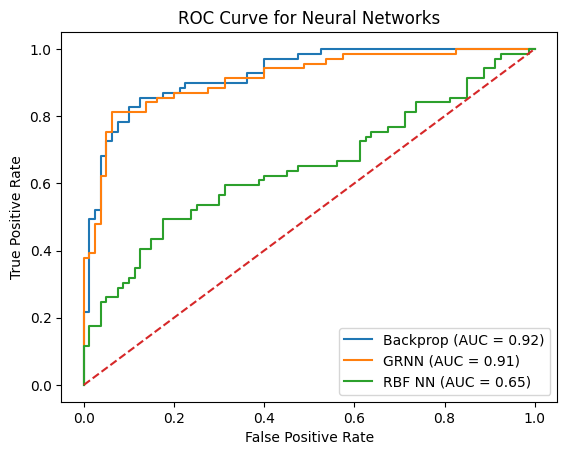

In [19]:
plt.figure()
plt.plot(fpr_bp, tpr_bp, label=f"Backprop (AUC = {auc_bp:.2f})")
plt.plot(fpr_grnn, tpr_grnn, label=f"GRNN (AUC = {auc_grnn:.2f})")
plt.plot(fpr_rbf_nn, tpr_rbf_nn, label=f"RBF NN (AUC = {auc_rbf_nn:.2f})")
plt.plot([0, 1], [0, 1], '--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve for Neural Networks")
plt.legend()
plt.show()

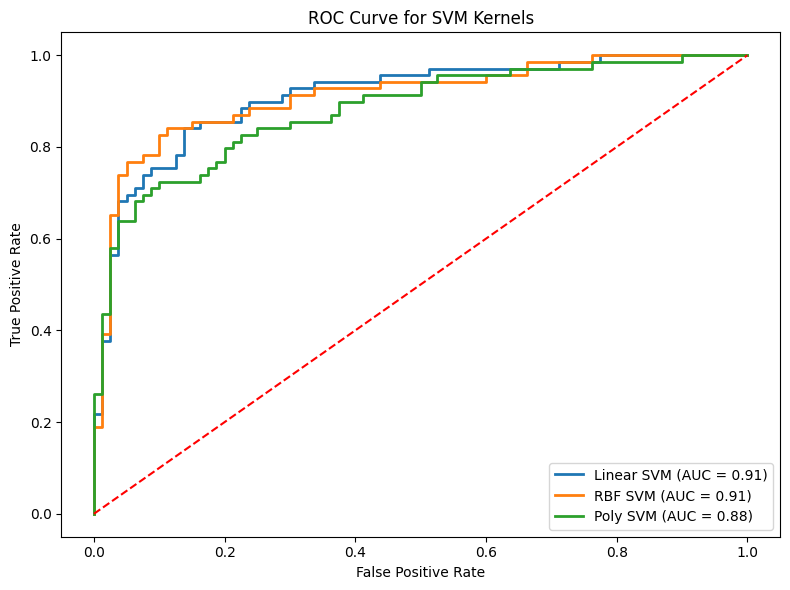

In [20]:
best_svm_models = {
    "Linear SVM": svm_linear_10,
    "RBF SVM": svm_rbf_10,
    "Poly SVM": svm_poly_10
}

plt.figure(figsize=(8, 6))

auc_linear = None
auc_rbf = None
auc_poly = None

for label, svm_model in best_svm_models.items():

    y_score = svm_model.predict_proba(X_test)[:, 1]

    fpr, tpr, _ = roc_curve(
        y_test,
        y_score
    )

    roc_auc = auc(
        fpr,
        tpr
    )

    if label == "Linear SVM":
        auc_linear = roc_auc

    elif label == "RBF SVM":
        auc_rbf = roc_auc

    elif label == "Poly SVM":
        auc_poly = roc_auc

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{label} (AUC = {roc_auc:.2f})"
    )

plt.plot([0, 1], [0, 1], 'r--', linewidth=1.5)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve for SVM Kernels")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


In [21]:
all_models = {
    "LR_10fold": lr_10fold,
    "Linear_SVM": svm_linear_10.best_estimator_,
    "RBF_SVM": svm_rbf_10.best_estimator_,
    "Poly_SVM": svm_poly_10.best_estimator_,
    "Backprop_NN": model,
    "RBF_NN": rbf_model
}

In [22]:
performance_df = pd.DataFrame({

    "Model": [

        "Logistic Regression",

        "Linear SVM",

        "RBF SVM",

        "Polynomial SVM",

        "Backprop NN",

        "RBF NN",

        "GRNN"
    ],

    "AUC": [

        auc_lr,

        auc_linear,

        auc_rbf,

        auc_poly,

        auc_bp,

        auc_rbf_nn,

        auc_grnn
    ]
})

performance_df = performance_df.sort_values(
    "AUC",
    ascending=False
)

print(performance_df)

                 Model       AUC
4          Backprop NN  0.924457
0  Logistic Regression  0.915217
6                 GRNN  0.913043
2              RBF SVM  0.911594
1           Linear SVM  0.911232
3       Polynomial SVM  0.880254
5               RBF NN  0.647826


In [23]:
# This is a descriptive test-set comparison, not a model-selection step.
test_auc_leader = performance_df.iloc[0]["Model"]
print(f"Highest observed test AUC (descriptive only): {test_auc_leader}")

Highest observed test AUC (descriptive only): Backprop NN


In [24]:
# Pre-specified XAI model: the 10-fold L2 logistic-regression variant.
# It is chosen from the replicated study design, not by inspecting the
# held-out test ranking above.
final_model = lr_10fold
selected_model_name = "Logistic Regression (10-fold CV)"

In [25]:
best_model = final_model

print("Final XAI model:", type(best_model).__name__)
print("Pre-specified model:", selected_model_name)
print("Selection did not use held-out test performance.")

Final XAI model: LogisticRegressionCV
Pre-specified model: Logistic Regression (10-fold CV)
Selection did not use held-out test performance.


In [26]:
from sklearn.base import clone

def train_model_fn(seed):

    model = clone(best_model)

    if hasattr(model, "random_state"):
        model.set_params(random_state=seed)

    model.fit(X_train, y_train)

    return model

In [27]:
from pathlib import Path
import sys

sys.path.append(str(Path.cwd().parents[1]))

from run_pipeline import run_pipeline

config = {
    "dataset_name": "heart",
    "model": best_model,

    "X_train": X_train,
    "X_test": X_test,

    "y_train": y_train,
    "y_test": y_test,

    "feature_names": feature_names,

    "train_model_fn": train_model_fn,

    "scoring": "roc_auc",

    "output_dir": "../../results/heart"
}

experiment = run_pipeline(config)

PermutationExplainer explainer: 150it [00:39,  3.73it/s]                         


Results exported to: ../../results/heart


# Validation

In [28]:
print("Dataset:", config["dataset_name"])
print("Model:", type(config["model"]).__name__)

print("X_train shape:", config["X_train"].shape)
print("X_test shape:", config["X_test"].shape)

print("y_train length:", len(config["y_train"]))
print("y_test length:", len(config["y_test"]))

print("Feature names:", len(config["feature_names"]))

Dataset: heart
Model: LogisticRegressionCV
X_train shape: (148, 13)
X_test shape: (149, 13)
y_train length: 148
y_test length: 149
Feature names: 13


#### Consistency

In [29]:
assert config["X_train"].shape[1] == len(config["feature_names"])
assert config["X_test"].shape[1] == len(config["feature_names"])

assert len(config["X_train"]) == len(config["y_train"])
assert len(config["X_test"]) == len(config["y_test"])

print("Basic shape validation: OK")

Basic shape validation: OK


#### Fitted model predicts on the configured data

In [30]:
model = config["model"]
X_test = config["X_test"]

if hasattr(model, "predict_proba"):
    probs = model.predict_proba(X_test)[:, 1]
    print("Probability range:", probs.min(), probs.max())

preds = model.predict(X_test)

print("Predictions:", np.unique(preds, return_counts=True))
print("Prediction test: OK")

Probability range: 0.26801784968312586 0.7620684993860655
Predictions: (array([0, 1]), array([80, 69]))
Prediction test: OK


#### Results from Framework

In [31]:
global_results = experiment.state.results["global"]
local_results = experiment.state.results["local"]
stability_results = experiment.state.results["stability"]

print(global_results.keys())
print(local_results.keys())

if stability_results is not None:
    print(stability_results.keys())
else:
    print("Stability: not available")

dict_keys(['native_importance', 'permutation_importance', 'shap_importance', 'shap_values', 'shap_raw_values', 'explainer', 'rank_compare', 'rank_agreement'])
dict_keys(['cases', 'lime'])
dict_keys(['raw', 'summary', 'rank_stability'])


#### Global XAI

In [32]:
native_df = global_results["native_importance"]
perm_df = global_results["permutation_importance"]
shap_df = global_results["shap_importance"]

print("Native:")
display(native_df.head())

print("Permutation:")
display(perm_df.head())

print("SHAP:")
display(shap_df.head())

Native:


,Feature,Importance,RawValue,Method
12,thal,0.153951,0.153951,coefficients
2,cp,0.130170,0.130170,coefficients
8,exang,0.114381,0.114381,coefficients
7,thalach,0.104741,-0.104741,coefficients
11,ca,0.100806,0.100806,coefficients


Permutation:


,Feature,Importance,Std
12,thal,0.035833,0.013175
11,ca,0.029493,0.008113
1,sex,0.014293,0.005012
7,thalach,0.011286,0.006377
2,cp,0.010707,0.008875


SHAP:


,Feature,MeanAbsSHAP,MeanSHAP
0,thal,0.036126,-0.002547
1,cp,0.026450,-0.001567
2,exang,0.025693,-0.001034
3,thalach,0.024344,0.005804
4,slope,0.022200,0.000468


#### Feature coverage

In [33]:
if native_df is not None:
    print("Native features:", len(native_df))

print("Permutation features:", len(perm_df))
print("SHAP features:", len(shap_df))
print("Expected features:", len(config["feature_names"]))

Native features: 13
Permutation features: 13
SHAP features: 13
Expected features: 13


#### Broken values

In [34]:
print("Permutation NaNs:", perm_df.isna().sum().sum())
print("SHAP NaNs:", shap_df.isna().sum().sum())

if native_df is not None:
    print("Native NaNs:", native_df.isna().sum().sum())

Permutation NaNs: 0
SHAP NaNs: 0
Native NaNs: 0


#### Rank agreement

In [35]:
print(global_results["rank_agreement"])

display(global_results["rank_compare"].head())

{'Native_vs_SHAP': np.float64(0.9780219780219779), 'Native_vs_Permutation': np.float64(0.6208791208791209), 'SHAP_vs_Permutation': np.float64(0.6153846153846153)}


,Feature,Importance_x,RawValue,Method,NativeRank,MeanAbsSHAP,MeanSHAP,SHAPRank,Importance_y,Std,PermutationRank
0,thal,0.153951,0.153951,coefficients,1.0,0.036126,-0.002547,1.0,0.035833,0.013175,1.0
1,cp,0.130170,0.130170,coefficients,2.0,0.026450,-0.001567,2.0,0.010707,0.008875,5.0
2,exang,0.114381,0.114381,coefficients,3.0,0.025693,-0.001034,3.0,0.005888,0.007579,7.0
3,thalach,0.104741,-0.104741,coefficients,4.0,0.024344,0.005804,4.0,0.011286,0.006377,4.0
4,ca,0.100806,0.100806,coefficients,5.0,0.022156,0.001607,6.0,0.029493,0.008113,2.0


#### Representative cases

In [36]:
cases = local_results["cases"]

display(
    cases[
        ["CaseType", "y_true", "y_pred", "y_prob"]
    ]
)

,CaseType,y_true,y_pred,y_prob
84,TP,1,1,0.762068
47,TN,0,0,0.268018
95,FP,0,1,0.677475
4,FN,1,0,0.364029
44,Borderline,0,1,0.500092


#### LIME

In [37]:
lime_df = local_results["lime"]

print("LIME rows:", len(lime_df))
display(lime_df.head())

LIME rows: 50


,CaseIndex,Prediction,Probability,Rule,Weight
0,84,1,0.762068,0.32 < cp <= 0.85,0.059946
1,84,1,0.762068,thalach <= -0.52,0.047814
2,84,1,0.762068,ca > 0.40,0.039839
3,84,1,0.762068,-0.70 < exang <= 1.42,0.038325
4,84,1,0.762068,-0.94 < thal <= 1.11,0.036612


#### Stability

In [38]:
if stability_results is not None:
    display(stability_results["raw"].head())
    print(stability_results["summary"])

,Feature,Importance,ImportanceStd,Seed,Rank
0,age,0.000978,0.002386,1,10.0
1,sex,0.014094,0.006878,1,3.0
2,cp,0.006359,0.007545,1,7.0
3,trestbps,0.000779,0.002603,1,11.0
4,chol,0.000254,0.000390,1,12.0


     Feature  MeanImportance  StdImportance  MeanRank   StdRank
10      thal        0.032243       0.001692       1.0  0.000000
1         ca        0.030478       0.001933       2.0  0.000000
8        sex        0.013007       0.001564       3.2  0.447214
11   thalach        0.011446       0.002081       4.2  1.095445
4      exang        0.009880       0.001006       5.2  0.836660
3         cp        0.008844       0.001979       6.0  1.000000
6    oldpeak        0.008170       0.001531       6.4  0.894427
9      slope        0.001931       0.000974       8.6  0.894427
12  trestbps        0.001391       0.000677       9.0  1.224745
0        age        0.000692       0.000535      10.4  1.140175
2       chol        0.000268       0.000095      11.0  0.707107
7    restecg        0.000152       0.001213      11.0  1.414214
5        fbs       -0.001793       0.000590      13.0  0.000000


#### Exported folder

In [39]:
from pathlib import Path

out_dir = Path(config["output_dir"]).resolve()

print("Output directory:", out_dir)

for path in sorted(out_dir.rglob("*")):
    if path.is_file():
        print(path.relative_to(out_dir))

Output directory: C:\Users\catia\Desktop\Blackboard\AASB\github\thesis\results\heart
bundle\metadata.json
bundle\model.pkl
bundle\X_test.csv
bundle\X_train.csv
bundle\y_test.csv
bundle\y_train.csv
lime_explanations.csv
model.pkl
native_importance.csv
permutation_importance.csv
rank_agreement\Native_vs_Permutation.json
rank_agreement\Native_vs_SHAP.json
rank_agreement\SHAP_vs_Permutation.json
rank_compare.csv
representative_cases.csv
shap_importance.csv
stability.csv
stability_rank.csv
stability_summary.csv


In [40]:
print(
    experiment.state.results["local"].keys()
)

dict_keys(['cases', 'lime'])


In [41]:
print(
    experiment.state.results["local"]["cases"].columns.tolist()
)

display(
    experiment.state.results["local"]["cases"]
)

['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'y_true', 'y_pred', 'y_prob', 'distance', 'CaseType', 'CaseIndex']


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,y_true,y_pred,y_prob,distance,CaseType,CaseIndex
84,-0.411115,0.619013,0.847174,0.506570,0.853934,-0.428952,-0.957016,-1.484606,1.421411,2.757194,0.703526,2.659046,1.114241,1,1,0.762068,0.262068,TP,84
47,-0.962248,-1.615474,-1.260082,-1.567766,-0.798811,-0.428952,-0.957016,0.932043,-0.703526,-0.915126,-0.949202,-0.733530,-0.940683,0,0,0.268018,0.231982,TN,47
95,1.021829,0.619013,0.847174,-0.204630,0.238550,-0.428952,-0.957016,-2.306267,1.421411,-0.740254,0.703526,0.397329,1.114241,0,1,0.677475,0.177475,FP,95
4,0.360470,-1.615474,-1.260082,0.269504,1.223165,2.331262,1.052039,-0.034617,-0.703526,-0.915126,-0.949202,1.528188,-0.940683,1,0,0.364029,0.135971,FN,4
44,-0.080436,0.619013,-0.206454,1.099238,-0.306504,-0.428952,1.052039,0.593712,-0.703526,0.483853,-0.949202,-0.733530,1.114241,0,1,0.500092,0.000092,Borderline,44


In [42]:
assert "CaseIndex" in experiment.state.results["local"]["cases"].columns

print("CaseIndex exists in memory.")

CaseIndex exists in memory.


In [43]:
heart_cases = pd.read_csv(
    Path("../../results/heart/representative_cases.csv")
)

print(heart_cases.columns.tolist())
display(heart_cases)

['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'y_true', 'y_pred', 'y_prob', 'distance', 'CaseType', 'CaseIndex']


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,y_true,y_pred,y_prob,distance,CaseType,CaseIndex
0,-0.411115,0.619013,0.847174,0.506570,0.853934,-0.428952,-0.957016,-1.484606,1.421411,2.757194,0.703526,2.659046,1.114241,1,1,0.762068,0.262068,TP,84
1,-0.962248,-1.615474,-1.260082,-1.567766,-0.798811,-0.428952,-0.957016,0.932043,-0.703526,-0.915126,-0.949202,-0.733530,-0.940683,0,0,0.268018,0.231982,TN,47
2,1.021829,0.619013,0.847174,-0.204630,0.238550,-0.428952,-0.957016,-2.306267,1.421411,-0.740254,0.703526,0.397329,1.114241,0,1,0.677475,0.177475,FP,95
3,0.360470,-1.615474,-1.260082,0.269504,1.223165,2.331262,1.052039,-0.034617,-0.703526,-0.915126,-0.949202,1.528188,-0.940683,1,0,0.364029,0.135971,FN,4
4,-0.080436,0.619013,-0.206454,1.099238,-0.306504,-0.428952,1.052039,0.593712,-0.703526,0.483853,-0.949202,-0.733530,1.114241,0,1,0.500092,0.000092,Borderline,44


In [44]:
import sys
import sklearn
import numpy
import pandas
import shap
import statsmodels

print("Python:", sys.executable)
print("Python version:", sys.version)
print("scikit-learn:", sklearn.__version__)
print("NumPy:", numpy.__version__)
print("pandas:", pandas.__version__)
print("SHAP:", shap.__version__)
print("statsmodels:", statsmodels.__version__)

Python: c:\Users\catia\AppData\Local\Programs\Python\Python312\python.exe
Python version: 3.12.6 (tags/v3.12.6:a4a2d2b, Sep  6 2024, 20:11:23) [MSC v.1940 64 bit (AMD64)]
scikit-learn: 1.6.1
NumPy: 2.1.3
pandas: 2.2.3
SHAP: 0.51.0
statsmodels: 0.14.6
